# 01 — ENSO event detection

Builds the 23-event catalog (10 El Niño, 13 La Niña) used throughout the paper.

1. Niño-3.4 (5°S–5°N, 170°W–120°W) monthly SST anomaly, linearly detrended over
   1979–2014, smoothed with a DJF centred 3-month running mean (ONI).
2. Classify every season (Weak ≥ 0.5, Moderate ≥ 1.0, Strong ≥ 1.5, Very Strong ≥ 2.0 °C).
3. Plot the full ONI time series.
4. Print the 12-season table.
5. Every year with |DJF| ≥ 0.5 °C becomes an event; seed `data/complete_wc_analysis.csv`
   with one row per (event, run).
6. Print every event ranked by |DJF| — the source of the representative pair
   (1983 El Niño, 1989 La Niña) hardcoded in `06`, `07`, `09`, `10`.

**Output:** `cfg.ANALYSIS_CSV_PATH` (seed columns `Year, Run, Event, Strength, DJF`).

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import xarray as xr
from scipy.signal import detrend
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Step 1 — Niño-3.4 anomaly → ONI

In [2]:
NINO34_LAT, NINO34_LON = (-5, 5), (190, 240)

ts = xr.open_dataset(cfg.AMIP_TS_1DEG_MASKED_PATH)["ts_regridded_masked"]
ts = ts.sel(time=slice("1979-01-01", "2014-12-31"))

# boolean mask instead of .sel(slice(...)): independent of coordinate ordering
box = ts.where((ts.lat >= NINO34_LAT[0]) & (ts.lat <= NINO34_LAT[1]) &
               (ts.lon >= NINO34_LON[0]) & (ts.lon <= NINO34_LON[1]), drop=True)
n34 = box.mean(["lat", "lon"]) - 273.15

clim = n34.groupby("time.month").mean("time")
anomaly = (n34.groupby("time.month") - clim).dropna("time")
anomaly.values[:] = detrend(anomaly.values)

oni = anomaly.rolling(time=3, center=True).mean().dropna("time").to_series()
oni.name = "nino34"
print(f"ONI computed for {oni.index[0].date()} - {oni.index[-1].date()} ({len(oni)} months)")

ONI computed for 1979-02-15 - 2014-11-16 (430 months)


## Step 2 — classify, and build the 12-season table

In [3]:
def classify(value):
    """ONI value -> (strength, event), e.g. ("Very Strong", "El Niño"); (None, None) if neutral."""
    for cut, strength in [(2.0, "Very Strong"), (1.5, "Strong"), (1.0, "Moderate"), (0.5, "Weak")]:
        if value >= cut:
            return strength, "El Niño"
        if value <= -cut:
            return strength, "La Niña"
    return None, None


SEASON_LABEL = {1: "DJF", 2: "JFM", 3: "FMA", 4: "MAM", 5: "AMJ", 6: "MJJ",
                7: "JJA", 8: "JAS", 9: "ASO", 10: "SON", 11: "OND", 12: "NDJ"}

table_df = oni.to_frame()
table_df["season"] = table_df.index.month.map(SEASON_LABEL)
table_df["season_year"] = table_df.index.year
table_df.loc[table_df.index.month == 12, "season_year"] += 1   # December belongs to next year's DJF

season_table = table_df.pivot_table(index="season_year", columns="season", values="nino34", aggfunc="mean")
season_table = season_table[list(SEASON_LABEL.values())]
season_table.head()

season,DJF,JFM,FMA,MAM,AMJ,MJJ,JJA,JAS,ASO,SON,OND,NDJ
season_year,,,,,,,,,,,,
1979,NaN,-0.045170,-0.025961,-0.092166,-0.141830,-0.269925,-0.192135,-0.043090,0.122751,0.162647,0.217643,NaN
1980,0.370713,0.221973,0.079316,-0.000530,0.050137,-0.010067,-0.139145,-0.281878,-0.331766,-0.236624,-0.099891,0.333957
1981,-0.312269,-0.399750,-0.344409,-0.251800,-0.328219,-0.411005,-0.441399,-0.393632,-0.268298,-0.380024,-0.443538,-0.169469
1982,-0.135561,-0.032460,-0.029354,0.180981,0.528777,0.726132,0.851571,0.936163,1.277765,1.610924,2.008907,-0.337244
1983,2.406768,2.161013,1.604945,1.150007,0.751425,0.363676,-0.048584,-0.322584,-0.542150,-0.792009,-1.011030,2.301389


## Step 3 — ONI time series

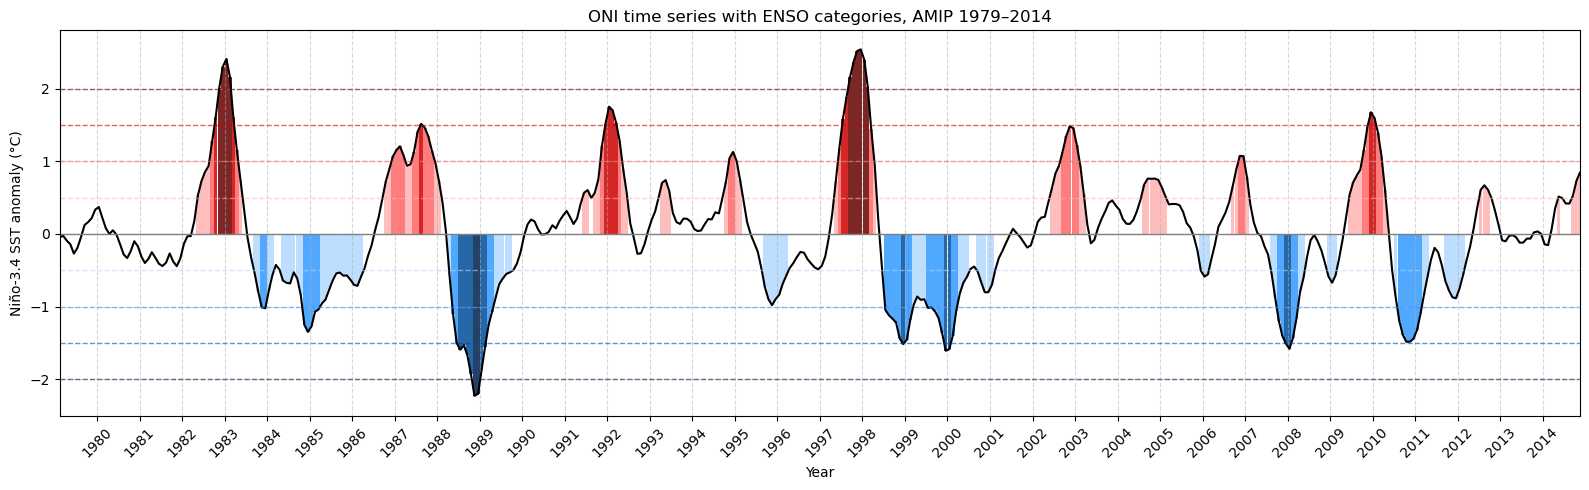

In [4]:
CATEGORY_COLOR = {
    "Weak El Niño": "#FFB3B3", "Moderate El Niño": "#FF6666",
    "Strong El Niño": "#CC0000", "Very Strong El Niño": "#660000",
    "Weak La Niña": "#B3D9FF", "Moderate La Niña": "#3399FF",
    "Strong La Niña": "#004C99", "Very Strong La Niña": "#001F4D",
}


def category_of(value):
    strength, event = classify(value)
    return f"{strength} {event}" if strength else None


plot_df = oni.reset_index()
plot_df.columns = ["time", "nino34"]
plot_df["category"] = plot_df["nino34"].apply(category_of)

plt.figure(figsize=(16, 5))
for cat, group in plot_df.dropna(subset=["category"]).groupby("category"):
    plt.bar(group["time"], group["nino34"], width=30, color=CATEGORY_COLOR[cat], alpha=0.85)
plt.plot(plot_df["time"], plot_df["nino34"], color="black", linewidth=1.5)

for threshold, cat in [(0.5, "Weak El Niño"), (1.0, "Moderate El Niño"), (1.5, "Strong El Niño"),
                       (2.0, "Very Strong El Niño"), (-0.5, "Weak La Niña"), (-1.0, "Moderate La Niña"),
                       (-1.5, "Strong La Niña"), (-2.0, "Very Strong La Niña")]:
    plt.axhline(threshold, color=CATEGORY_COLOR[cat], linestyle="--", linewidth=1, alpha=0.6)

plt.axhline(0, color="gray", linewidth=1)
ax = plt.gca()
ax.set_xlim(plot_df["time"].min(), plot_df["time"].max())
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.ylim(-2.5, 2.8)
plt.title("ONI time series with ENSO categories, AMIP 1979–2014")
plt.ylabel("Niño-3.4 SST anomaly (°C)")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

## Step 4 — seasonal table

In [5]:
print(season_table.round(2).to_string())

season        DJF   JFM   FMA   MAM   AMJ   MJJ   JJA   JAS   ASO   SON   OND   NDJ
season_year                                                                        
1979          NaN -0.05 -0.03 -0.09 -0.14 -0.27 -0.19 -0.04  0.12  0.16  0.22   NaN
1980         0.37  0.22  0.08 -0.00  0.05 -0.01 -0.14 -0.28 -0.33 -0.24 -0.10  0.33
1981        -0.31 -0.40 -0.34 -0.25 -0.33 -0.41 -0.44 -0.39 -0.27 -0.38 -0.44 -0.17
1982        -0.14 -0.03 -0.03  0.18  0.53  0.73  0.85  0.94  1.28  1.61  2.01 -0.34
1983         2.41  2.16  1.60  1.15  0.75  0.36 -0.05 -0.32 -0.54 -0.79 -1.01  2.30
1984        -0.77 -0.57 -0.43 -0.49 -0.64 -0.67 -0.68 -0.53 -0.61 -0.85 -1.25 -1.02
1985        -1.27 -1.07 -1.04 -0.95 -0.90 -0.77 -0.64 -0.54 -0.53 -0.57 -0.57 -1.35
1986        -0.70 -0.71 -0.59 -0.48 -0.30 -0.16  0.05  0.24  0.48  0.72  0.90 -0.63
1987         1.16  1.20  1.09  0.94  0.96  1.13  1.41  1.51  1.46  1.34  1.15  1.07
1988         0.72  0.43  0.02 -0.58 -1.11 -1.50 -1.59 -1.53 -1.67 -1.92 -2.2

## Step 5 — seed the analysis table (|DJF| ≥ 0.5 °C)

In [6]:
RUNS = ["Full Run", "Uniform Run", "Pattern Run"]

djf = season_table["DJF"].dropna()
events = djf[djf.abs() >= 0.5]

rows = []
for year, value in events.items():
    strength, event = classify(value)
    for run in RUNS:
        rows.append({"Year": int(year), "Run": run, "Event": event, "Strength": strength, "DJF": round(float(value), 2)})
seed_df = pd.DataFrame(rows)

seed_cols = ["Year", "Run", "Event", "Strength", "DJF"]
os.makedirs(cfg.ANALYSIS_DIR, exist_ok=True)
if os.path.exists(cfg.ANALYSIS_CSV_PATH):
    existing = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
    extra_cols = [c for c in existing.columns if c not in seed_cols]
    if extra_cols:
        seed_df = seed_df.merge(existing[["Year", "Run"] + extra_cols], on=["Year", "Run"], how="left")

seed_df.to_csv(cfg.ANALYSIS_CSV_PATH, index=False)
n_el = seed_df.drop_duplicates("Year")["Event"].eq("El Niño").sum()
print(f"saved {len(seed_df)} rows: {seed_df['Year'].nunique()} events ({n_el} El Niño) -> {cfg.ANALYSIS_CSV_PATH}")

saved 69 rows: 23 events (10 El Niño) -> /work/mh1421/m301201/enso-tug-of-war/walker-tug-of-war/data/complete_wc_analysis.csv


## Step 6 — events ranked by |DJF|

In [7]:
events_only = seed_df.drop_duplicates(subset=["Year"])
for sign in ["El Niño", "La Niña"]:
    subset = events_only[events_only["Event"] == sign]
    ranked = subset.loc[subset["DJF"].abs().sort_values(ascending=False).index]
    print(f"\n{sign}, strongest to weakest:")
    print(ranked[["Year", "Strength", "DJF"]].to_string(index=False))


El Niño, strongest to weakest:
 Year    Strength  DJF
 1983 Very Strong 2.41
 1998 Very Strong 2.40
 1992      Strong 1.75
 2010      Strong 1.59
 2003    Moderate 1.22
 1987    Moderate 1.16
 1995        Weak 1.00
 2007        Weak 0.78
 1988        Weak 0.72
 2005        Weak 0.63

La Niña, strongest to weakest:
 Year Strength   DJF
 1989   Strong -1.87
 2000   Strong -1.59
 2008   Strong -1.58
 1999 Moderate -1.46
 2011 Moderate -1.32
 1985 Moderate -1.27
 1996     Weak -0.84
 1984     Weak -0.77
 2012     Weak -0.75
 1986     Weak -0.70
 2001     Weak -0.70
 2009     Weak -0.67
 2006     Weak -0.59
